# Kural — Exploratory Data Analysis

This notebook performs exploratory data analysis (EDA) on the prepared financial complaint dataset (`complaints_clean.csv.gz`). It investigates complaint distribution across products, issues, companies, time periods, recorded responses, and narrative characteristics.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paths
figures_dir = Path('../outputs/figures')
tables_dir = Path('../outputs/tables')
data_path = Path('../data/processed/complaints_clean.csv.gz')

figures_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"Data path exists: {data_path.exists()}")

Data path exists: True


In [2]:
df = pd.read_csv(data_path)
df['date_received'] = pd.to_datetime(df['date_received'])
print(f"Loaded prepared dataset: {len(df):,} records, {len(df.columns)} fields.")

Loaded prepared dataset: 117,214 records, 26 fields.


## 1. Dataset Overview

In this section, we examine key dimensions of the prepared complaints dataset:
- Total records and fields
- Date range covered
- Distinct product categories and companies
- Missing value counts across critical operational fields

In [3]:
date_min = df['date_received'].min().strftime('%Y-%m-%d')
date_max = df['date_received'].max().strftime('%Y-%m-%d')
n_products = df['product'].nunique()
n_companies = df['company'].nunique()

overview_metrics = {
    'Total Records': f"{len(df):,}",
    'Total Fields': len(df.columns),
    'Date Range': f"{date_min} to {date_max}",
    'Number of Products': n_products,
    'Number of Companies': f"{n_companies:,}"
}

print("=== DATASET OVERVIEW ===")
for k, v in overview_metrics.items():
    print(f"  {k:22}: {v}")

important_fields = [
    'complaint_id', 'date_received', 'product', 'issue',
    'company', 'company_response_to_consumer', 'timely_response', 'cleaned_narrative'
]
print("\nMissing values in important fields:")
for field in important_fields:
    missing_cnt = df[field].isna().sum()
    print(f"  {field:30}: {missing_cnt:,} ({missing_cnt/len(df):.2%})")

=== DATASET OVERVIEW ===
  Total Records         : 117,214
  Total Fields          : 26
  Date Range            : 2019-01-01 to 2020-01-09
  Number of Products    : 9
  Number of Companies   : 2,541

Missing values in important fields:
  complaint_id                  : 0 (0.00%)
  date_received                 : 0 (0.00%)
  product                       : 0 (0.00%)
  issue                         : 0 (0.00%)
  company                       : 0 (0.00%)
  company_response_to_consumer  : 0 (0.00%)
  timely_response               : 0 (0.00%)
  cleaned_narrative             : 0 (0.00%)


## 2. Complaint Distribution

We analyze how complaint volumes are distributed across:
- Financial product categories
- Most frequent complaint issues
- Monthly timeline (highlighting complete vs. partial periods)
- Top financial institutions receiving complaints

Saved outputs/tables/complaints_by_product.csv


,product,complaint_count,percentage
0,"Credit reporting, credit repair services, or o...",55558,47.40
1,Debt collection,22287,19.01
2,Credit card or prepaid card,11571,9.87
3,Mortgage,9449,8.06
4,Checking or savings account,6915,5.90
5,Student loan,3941,3.36
6,Vehicle loan or lease,2713,2.31
7,"Money transfer, virtual currency, or money ser...",2563,2.19
8,"Payday loan, title loan, or personal loan",2217,1.89


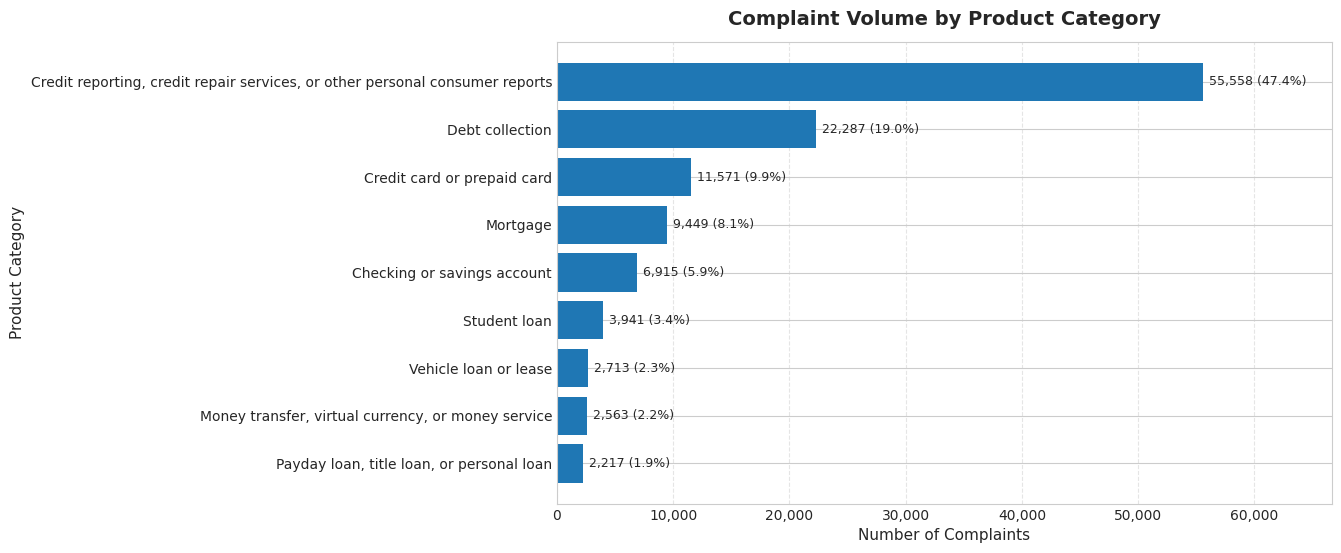

Saved outputs/figures/complaints_by_product.png


In [4]:
# Complaints by product
prod_summary = df['product'].value_counts().reset_index()
prod_summary.columns = ['product', 'complaint_count']
prod_summary['percentage'] = (prod_summary['complaint_count'] / len(df) * 100).round(2)

# Export analytical table
prod_summary.to_csv(tables_dir / 'complaints_by_product.csv', index=False)
print("Saved outputs/tables/complaints_by_product.csv")
display(prod_summary)

# Chart 1: Complaint Volume by Product
fig, ax = plt.subplots(figsize=(10, 6))
prod_counts_asc = df['product'].value_counts(ascending=True)
bars = ax.barh(prod_counts_asc.index, prod_counts_asc.values, color='#1f77b4', edgecolor='none')
ax.set_title('Complaint Volume by Product Category', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Number of Complaints', fontsize=11)
ax.set_ylabel('Product Category', fontsize=11)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    pct = w / len(df) * 100
    ax.text(w + 500, bar.get_y() + bar.get_height() / 2, f'{w:,.0f} ({pct:.1f}%)', va='center', fontsize=9)

ax.set_xlim(0, prod_counts_asc.max() * 1.20)
plt.savefig(figures_dir / 'complaints_by_product.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/complaints_by_product.png")

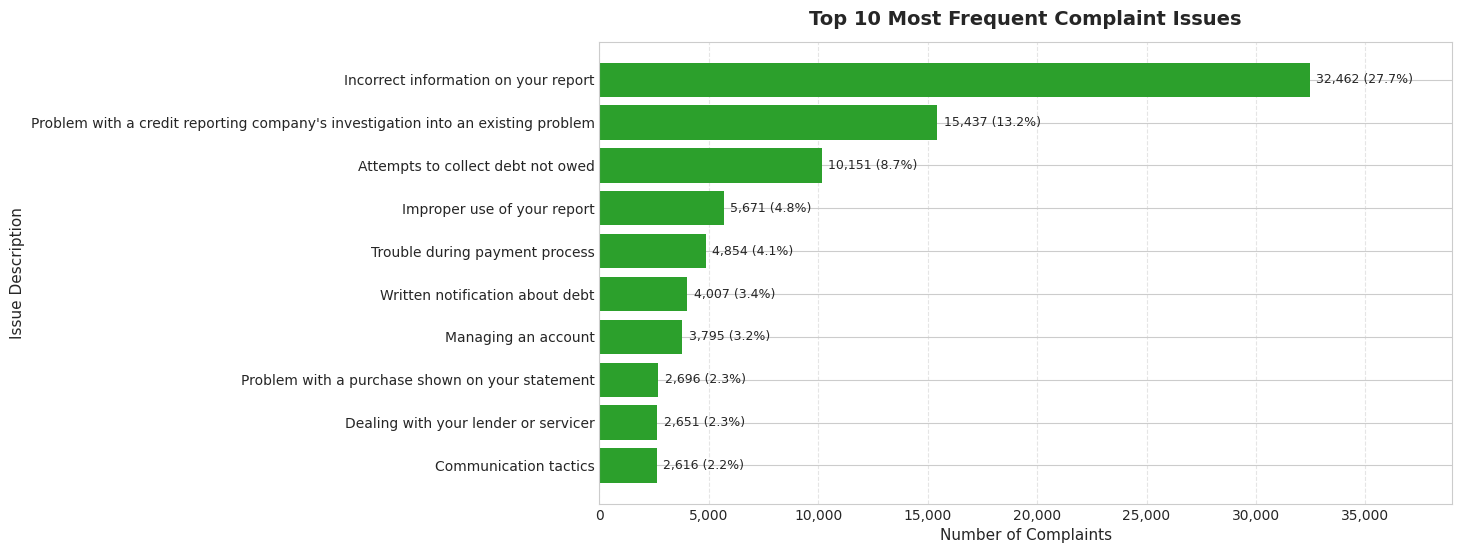

Saved outputs/figures/most_frequent_issues.png


In [5]:
# Top 10 Most Frequent Issues
top_issues = df['issue'].value_counts().head(10).sort_values(ascending=True)

# Chart 3: Most Frequent Complaint Issues
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(top_issues.index, top_issues.values, color='#2ca02c', edgecolor='none')
ax.set_title('Top 10 Most Frequent Complaint Issues', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Number of Complaints', fontsize=11)
ax.set_ylabel('Issue Description', fontsize=11)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    pct = w / len(df) * 100
    ax.text(w + 300, bar.get_y() + bar.get_height() / 2, f'{w:,.0f} ({pct:.1f}%)', va='center', fontsize=9)

ax.set_xlim(0, top_issues.max() * 1.20)
plt.savefig(figures_dir / 'most_frequent_issues.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/most_frequent_issues.png")

Saved outputs/tables/monthly_complaints.csv

,year_month,complaint_count,is_partial_month,notes
0,2019-01,8533,False,Full month
1,2019-02,9618,False,Full month
2,2019-03,10370,False,Full month
3,2019-04,10095,False,Full month
4,2019-05,10475,False,Full month
5,2019-06,10615,False,Full month
6,2019-07,11174,False,Full month
7,2019-08,12066,False,Full month
8,2019-09,10351,False,Full month
9,2019-10,11697,False,Full month


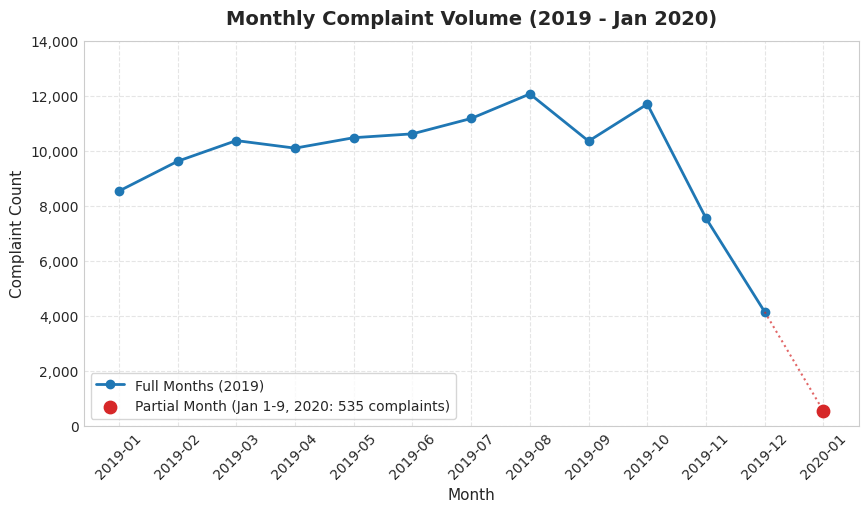

Saved outputs/figures/monthly_complaint_volume.png


In [6]:
# Monthly Complaint Volumes
df['year_month'] = df['date_received'].dt.to_period('M').astype(str)
monthly_summary = df['year_month'].value_counts().sort_index().reset_index()
monthly_summary.columns = ['year_month', 'complaint_count']
monthly_summary['is_partial_month'] = monthly_summary['year_month'] == '2020-01'
monthly_summary['notes'] = monthly_summary['is_partial_month'].apply(
    lambda x: 'Partial month (Jan 1 - Jan 9, 2020)' if x else 'Full month'
)

# Export analytical table
monthly_summary.to_csv(tables_dir / 'monthly_complaints.csv', index=False)
print("Saved outputs/tables/monthly_complaints.csv")
display(monthly_summary)

# Chart 2: Monthly Complaint Volume
monthly = df['year_month'].value_counts().sort_index()
full_months = monthly[monthly.index != '2020-01']
partial_month = monthly[monthly.index == '2020-01']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(full_months.index, full_months.values, marker='o', color='#1f77b4', linewidth=2, label='Full Months (2019)')
ax.scatter(partial_month.index, partial_month.values, color='#d62728', s=80, zorder=5, label='Partial Month (Jan 1-9, 2020: 535 complaints)')
ax.plot([full_months.index[-1], partial_month.index[0]], [full_months.values[-1], partial_month.values[0]], linestyle=':', color='#d62728', alpha=0.7)

ax.set_title('Monthly Complaint Volume (2019 - Jan 2020)', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Complaint Count', fontsize=11)
ax.set_ylim(0, 14000)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
ax.legend(loc='lower left', frameon=True)

plt.savefig(figures_dir / 'monthly_complaint_volume.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/monthly_complaint_volume.png")

In [7]:
# Companies with Highest Complaint Counts
top_companies = df['company'].value_counts().head(10).reset_index()
top_companies.columns = ['company', 'complaint_count']
top_companies['percentage'] = (top_companies['complaint_count'] / len(df) * 100).round(2)
display(top_companies)

,company,complaint_count,percentage
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",15237,13.00
1,"EQUIFAX, INC.",14607,12.46
2,Experian Information Solutions Inc.,14290,12.19
3,"CITIBANK, N.A.",3359,2.87
4,CAPITAL ONE FINANCIAL CORPORATION,3281,2.80
5,JPMORGAN CHASE & CO.,3104,2.65
6,"BANK OF AMERICA, NATIONAL ASSOCIATION",2830,2.41
7,WELLS FARGO & COMPANY,2821,2.41
8,SYNCHRONY FINANCIAL,2372,2.02
9,"Navient Solutions, LLC.",2057,1.75


## 3. Response Analysis

In this section, we examine operational response records:
- Categories of company responses recorded by CFPB
- Timeliness of company responses (whether responses met CFPB timeliness thresholds)
- Timely response rates broken down across product lines

*Note on definitions:* A recorded response category such as "Closed with explanation" reflects the company's administrative closure status as reported to CFPB. It should not be interpreted as verification that the customer's grievance was resolved satisfactorily.

Saved outputs/tables/response_summary.csv


,company_response_to_consumer,complaint_count,percentage
0,Closed with explanation,94941,81.00
1,Closed with non-monetary relief,16437,14.02
2,Closed with monetary relief,5118,4.37
3,Untimely response,718,0.61


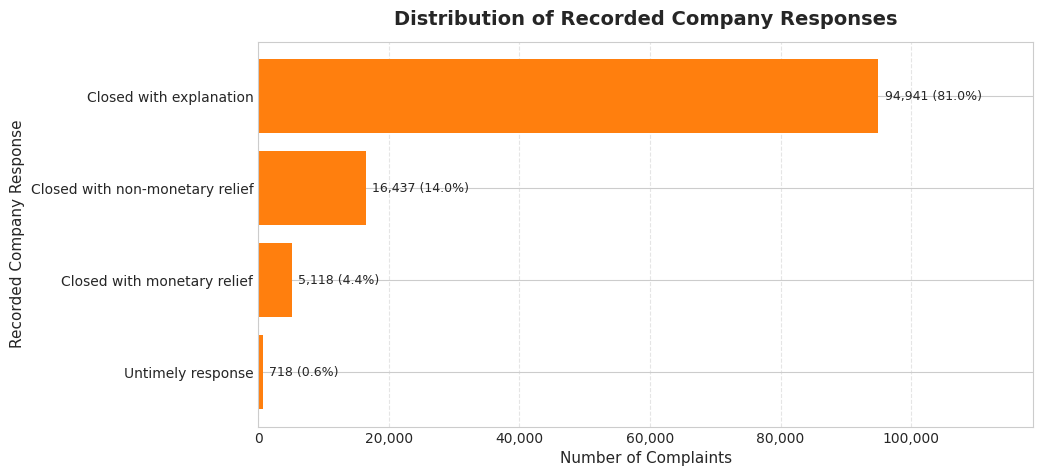

Saved outputs/figures/company_responses.png


In [8]:
# Recorded company response categories
resp_summary = df['company_response_to_consumer'].value_counts().reset_index()
resp_summary.columns = ['company_response_to_consumer', 'complaint_count']
resp_summary['percentage'] = (resp_summary['complaint_count'] / len(df) * 100).round(2)

# Export analytical table
resp_summary.to_csv(tables_dir / 'response_summary.csv', index=False)
print("Saved outputs/tables/response_summary.csv")
display(resp_summary)

# Chart 4: Recorded Company Responses
resp_counts = df['company_response_to_consumer'].value_counts(ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(resp_counts.index, resp_counts.values, color='#ff7f0e', edgecolor='none')
ax.set_title('Distribution of Recorded Company Responses', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Number of Complaints', fontsize=11)
ax.set_ylabel('Recorded Company Response', fontsize=11)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    pct = w / len(df) * 100
    ax.text(w + 1000, bar.get_y() + bar.get_height() / 2, f'{w:,.0f} ({pct:.1f}%)', va='center', fontsize=9)

ax.set_xlim(0, resp_counts.max() * 1.25)
plt.savefig(figures_dir / 'company_responses.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/company_responses.png")

,timely_response,count,percentage
0,Yes,115136,98.23
1,No,2078,1.77


Saved outputs/tables/product_timely_response.csv


,product,total_complaints,timely_count,untimely_count,timely_percentage
2,"Credit reporting, credit repair services, or o...",55558,55120,438,99.21
3,Debt collection,22287,21352,935,95.80
1,Credit card or prepaid card,11571,11495,76,99.34
5,Mortgage,9449,9310,139,98.53
0,Checking or savings account,6915,6795,120,98.26
7,Student loan,3941,3855,86,97.82
8,Vehicle loan or lease,2713,2647,66,97.57
4,"Money transfer, virtual currency, or money ser...",2563,2505,58,97.74
6,"Payday loan, title loan, or personal loan",2217,2057,160,92.78


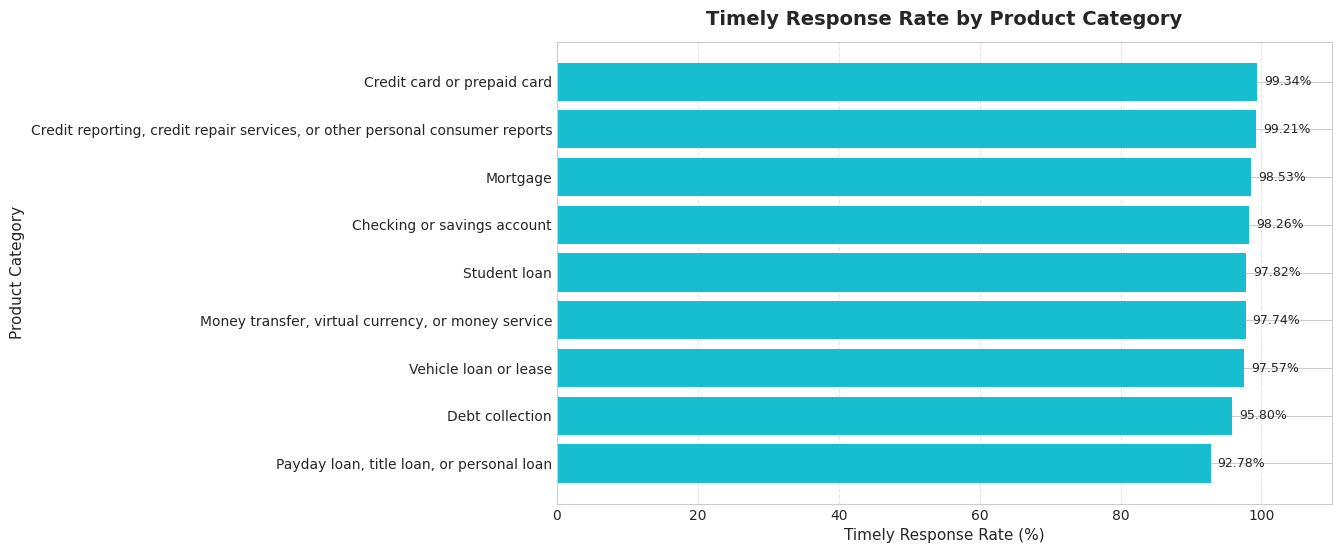

Saved outputs/figures/timely_response_by_product.png


In [9]:
# Timely-response distribution
timely_dist = df['timely_response'].value_counts().reset_index()
timely_dist.columns = ['timely_response', 'count']
timely_dist['percentage'] = (timely_dist['count'] / len(df) * 100).round(2)
display(timely_dist)

# Product timely response breakdown
pt = df.groupby('product')['timely_response'].value_counts().unstack(fill_value=0).reset_index()
pt.columns = ['product', 'untimely_count', 'timely_count']
pt['total_complaints'] = pt['timely_count'] + pt['untimely_count']
pt['timely_percentage'] = (pt['timely_count'] / pt['total_complaints'] * 100).round(2)
pt = pt[['product', 'total_complaints', 'timely_count', 'untimely_count', 'timely_percentage']]
pt = pt.sort_values(by='total_complaints', ascending=False)

# Export analytical table
pt.to_csv(tables_dir / 'product_timely_response.csv', index=False)
print("Saved outputs/tables/product_timely_response.csv")
display(pt)

# Chart 5: Timely-Response Percentage by Product
prod_timely = pt.sort_values(by='timely_percentage', ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(prod_timely['product'], prod_timely['timely_percentage'], color='#17becf', edgecolor='none')
ax.set_title('Timely Response Rate by Product Category', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Timely Response Rate (%)', fontsize=11)
ax.set_ylabel('Product Category', fontsize=11)
ax.set_xlim(0, 110)
ax.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1, bar.get_y() + bar.get_height() / 2, f'{w:.2f}%', va='center', fontsize=9)

plt.savefig(figures_dir / 'timely_response_by_product.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/timely_response_by_product.png")

## 4. Narrative Analysis

In this section, we analyze customer complaint narratives:
- Distribution of narrative word counts (summary statistics and skewness)
- Assessment of missing or blank narratives
- Assessment of duplicate and templated narratives
- Comparison of narrative lengths across product categories

=== NARRATIVE WORD COUNT SUMMARY ===
count    117214.000000
mean        192.537163
std         243.122008
min           1.000000
25%          65.000000
50%         123.000000
75%         229.000000
90%         408.000000
95%         603.000000
99%        1155.870000
max        6014.000000
Name: narrative_word_count, dtype: float64



Missing narratives count:         0
Unique narratives count:          106,360
Duplicate narrative records:      10,854 (subsequent occurrences)
Total records sharing text:       15,765 (records with non-unique narrative text)


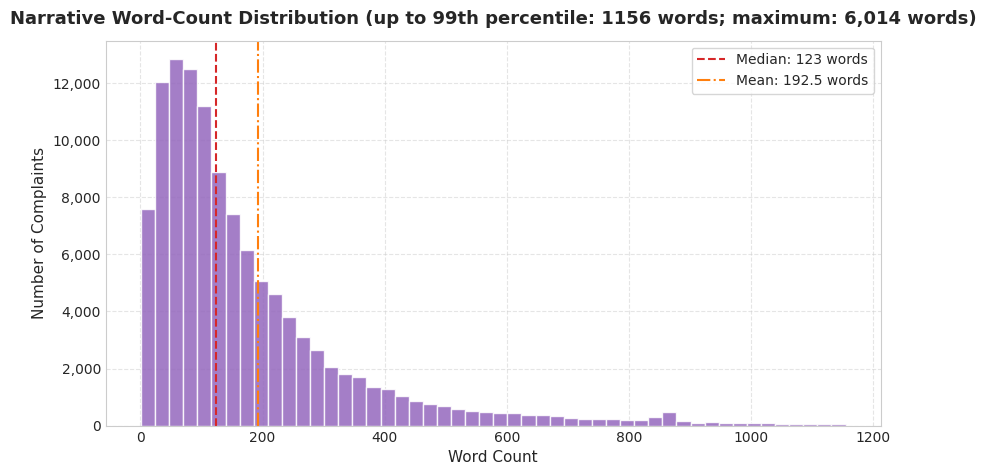

Saved outputs/figures/narrative_word_count_distribution.png


In [10]:
# Narrative word-count summary statistics
word_stats = df['narrative_word_count'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
print("=== NARRATIVE WORD COUNT SUMMARY ===")
print(word_stats)

empty_narratives = int(df['is_missing_narrative'].sum())
dup_narratives_subsequent = int(df['is_duplicate_narrative'].sum())
dup_narratives_all = int(df['consumer_complaint_narrative'].duplicated(keep=False).sum())
unique_narratives = int(df['consumer_complaint_narrative'].nunique())

print(f"\nMissing narratives count:         {empty_narratives}")
print(f"Unique narratives count:          {unique_narratives:,}")
print(f"Duplicate narrative records:      {dup_narratives_subsequent:,} (subsequent occurrences)")
print(f"Total records sharing text:       {dup_narratives_all:,} (records with non-unique narrative text)")

# Chart 6: Narrative Word-Count Distribution
p99 = df['narrative_word_count'].quantile(0.99)
max_words = int(df['narrative_word_count'].max())
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df[df['narrative_word_count'] <= p99]['narrative_word_count'], bins=50, color='#9467bd', edgecolor='white', alpha=0.85)

median_words = df['narrative_word_count'].median()
mean_words = df['narrative_word_count'].mean()
ax.axvline(median_words, color='#d62728', linestyle='--', linewidth=1.5, label=f'Median: {median_words:.0f} words')
ax.axvline(mean_words, color='#ff7f0e', linestyle='-.', linewidth=1.5, label=f'Mean: {mean_words:.1f} words')

ax.set_title(f'Narrative Word-Count Distribution (up to 99th percentile: {p99:.0f} words; maximum: {max_words:,} words)', fontsize=13, pad=12, fontweight='bold')
ax.set_xlabel('Word Count', fontsize=11)
ax.set_ylabel('Number of Complaints', fontsize=11)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True)

plt.savefig(figures_dir / 'narrative_word_count_distribution.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved outputs/figures/narrative_word_count_distribution.png")

In [11]:
# Narrative word count comparison across product categories
narrative_by_prod = df.groupby('product')['narrative_word_count'].agg(
    complaint_count='count',
    mean_words='mean',
    median_words='median',
    std_words='std',
    min_words='min',
    max_words='max'
).sort_values(by='mean_words', ascending=False).reset_index()

narrative_by_prod['mean_words'] = narrative_by_prod['mean_words'].round(1)
narrative_by_prod['median_words'] = narrative_by_prod['median_words'].round(1)
narrative_by_prod['std_words'] = narrative_by_prod['std_words'].round(1)

display(narrative_by_prod)

,product,complaint_count,mean_words,median_words,std_words,min_words,max_words
0,Mortgage,9449,322.7,223.0,370.4,1,5882
1,Checking or savings account,6915,255.4,179.0,287.9,1,6014
2,"Money transfer, virtual currency, or money ser...",2563,242.0,170.0,281.1,1,3808
3,Credit card or prepaid card,11571,241.8,174.0,258.5,1,4416
4,Vehicle loan or lease,2713,241.7,176.0,233.8,1,2395
5,Student loan,3941,238.0,175.0,230.6,1,3727
6,"Payday loan, title loan, or personal loan",2217,205.3,143.0,225.9,1,3171
7,Debt collection,22287,169.3,115.0,193.9,1,5295
8,"Credit reporting, credit repair services, or o...",55558,153.2,95.0,209.6,1,5426


## 5. Initial Observations

Based strictly on empirical evidence from the 117,214 complaints analyzed:

1. **Product Concentration:** Complaints are heavily concentrated in credit reporting and debt collection. "Credit reporting, credit repair services, or other personal consumer reports" represents 55,558 complaints (47.40%), and "Debt collection" represents 22,287 complaints (19.01%). Together, these two categories constitute nearly two-thirds (66.41%) of all recorded complaints.
2. **Institutional Exposure:** The top three entities receiving complaints are the nationwide consumer reporting agencies: TransUnion Intermediate Holdings (15,237 complaints), Equifax (14,607 complaints), and Experian (14,290 complaints). Combined, these three companies account for 44,134 complaints (37.65% of all complaints).
3. **Company Response Distribution:** The vast majority of complaints (94,941, or 81.00%) are closed with an explanation ("Closed with explanation"). Non-monetary relief was provided in 16,437 complaints (14.02%), monetary relief was granted in 5,118 complaints (4.37%), and 718 complaints (0.61%) received untimely responses.
4. **Response Timeliness:** Overall response timeliness across all companies is high at 98.23% (115,136 timely responses out of 117,214). However, timeliness varies by product: "Credit card or prepaid card" achieves the highest timeliness rate at 99.34%, whereas "Payday loan, title loan, or personal loan" records the lowest at 92.78% (with 160 untimely responses out of 2,217).
5. **Narrative Length Variation:** Narrative word counts are strongly right-skewed, with an overall median of 123 words, a mean of 192.5 words, and a maximum of 6,014 words. Complex financial products require more detailed descriptions from consumers; for example, Mortgage complaints average 322.7 words (median 223), whereas Credit reporting complaints average 153.2 words (median 95).
6. **Presence of Duplicate Narratives:** There are 10,854 duplicate narrative occurrences in the dataset (with 15,765 total records sharing identical narrative text across 106,360 distinct narratives), pointing to consumer use of standardized dispute templates and credit repair form letters.